# 📊 Analyse des séries temporelles

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 11h20** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Suivre la tendance du chiffre d'affaires avec des moyennes mobiles
- Mesurer la saisonnalité par décomposition
- Détecter une rupture et l'expliquer par les données

**Maison Lumen — Soualiho KAMAGATÉ et Julien FOURNIER**

In [1]:
import os, sys, subprocess, importlib.util
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "statsmodels", "fairlearn", "gdown"]:
    if importlib.util.find_spec(paquet) is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",paquet])
CONFIG_ID="1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"
if not os.path.exists("config_projet.py"):
    import gdown
    gdown.download(id=CONFIG_ID,output="config_projet.py",quiet=True)
print("✅ Configuration prête")

In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")
from pathlib import Path
from IPython.display import display, Markdown
evenement=pd.Timestamp(cfg["evenement"][0])
sensibles=cfg["sensibles"]


Maison Lumen · 24224 lignes, 16 colonnes


## 1. Le chiffre d'affaires mensuel
Agrégez par mois (`resample("MS")`) et tracez la courbe.

,Chiffre d’affaires (€)
date_commande,
2023-01-01,36376.07
2023-02-01,30709.75
2023-03-01,38650.15
2023-04-01,39735.58
2023-05-01,42090.72
2023-06-01,45107.88
2023-07-01,33446.07
2023-08-01,30866.18
2023-09-01,45643.06


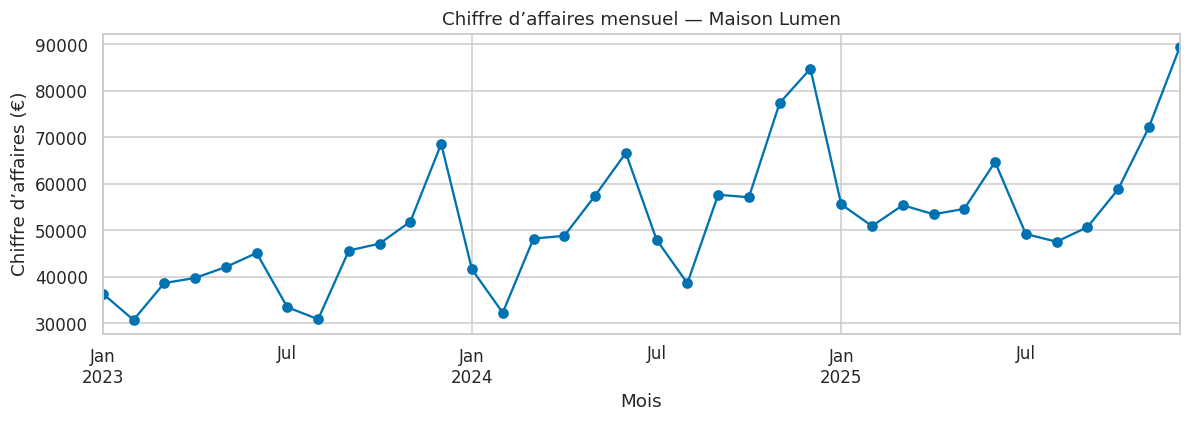

24224 → 24089 ; lignes retirées : 135
Doublons exacts : 121 ; avoirs négatifs après dédoublonnage : 14


In [3]:
df=nettoyage_minimal(brut,cfg)
df["region"]=df.region.fillna("inconnu")
df["apres"]=df.date_commande.ge(evenement).astype(int)
df["periode"]=np.where(df.apres.eq(1),"Après refonte","Avant refonte")
print(len(brut),"→",len(df),"; lignes retirées :",len(brut)-len(df))
print("Doublons exacts :",brut.duplicated().sum(),"; avoirs négatifs après dédoublonnage :",brut.drop_duplicates().montant_eur.lt(0).sum())
mensuel = df.set_index(cfg["date"])[cfg["ca"]].resample("MS").sum(min_count=1)
assert len(mensuel) == 36 and mensuel.notna().all()
display(mensuel.to_frame("Chiffre d’affaires (€)").round(2))
ax = mensuel.plot(figsize=(11,4), marker="o", color="#0072B2")
ax.set(title="Chiffre d’affaires mensuel — Maison Lumen", xlabel="Mois", ylabel="Chiffre d’affaires (€)")
plt.tight_layout(); plt.show()

## 2. Les moyennes mobiles
Ajoutez une moyenne mobile sur 3 mois et une sur 12 mois. Que montre chacune ?

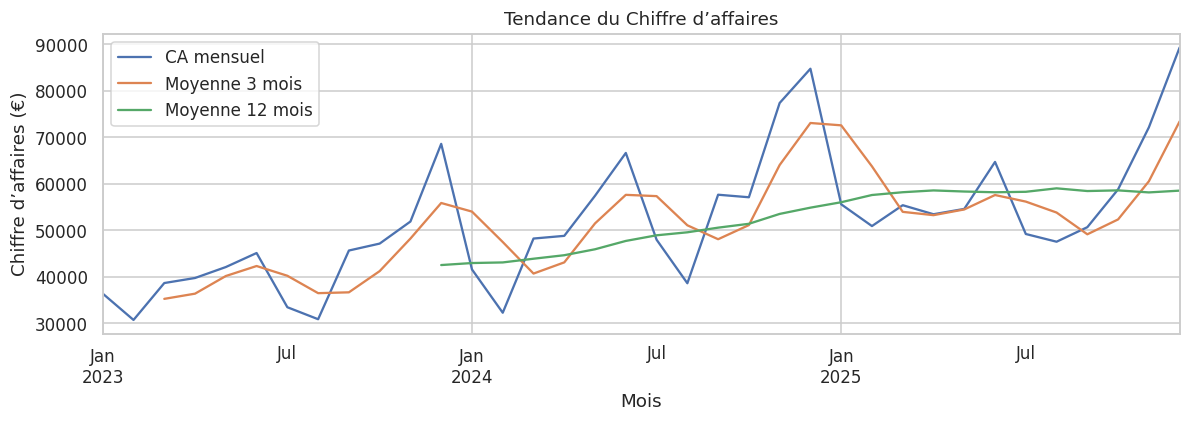

La moyenne sur 3 mois lisse les variations courtes ; celle sur 12 mois donne la tendance annuelle avec retard.


In [4]:
mm3 = mensuel.rolling(3, min_periods=3).mean()
mm12 = mensuel.rolling(12, min_periods=12).mean()
ax = pd.DataFrame({"CA mensuel":mensuel,"Moyenne 3 mois":mm3,"Moyenne 12 mois":mm12}).plot(figsize=(11,4))
ax.set(title="Tendance du Chiffre d’affaires", xlabel="Mois", ylabel="Chiffre d’affaires (€)")
plt.tight_layout(); plt.show()
print("La moyenne sur 3 mois lisse les variations courtes ; celle sur 12 mois donne la tendance annuelle avec retard.")

## 3. La décomposition saisonnière
Un événement exceptionnel fausse les coefficients saisonniers : remplacez d'abord les mois atypiques listés dans `cfg["atypiques"]` (les Jeux olympiques pour Les Escales) par la moyenne du même mois les autres années. Puis décomposez (`period=12`). Modèle additif ou multiplicatif : lequel convient, et pourquoi ?

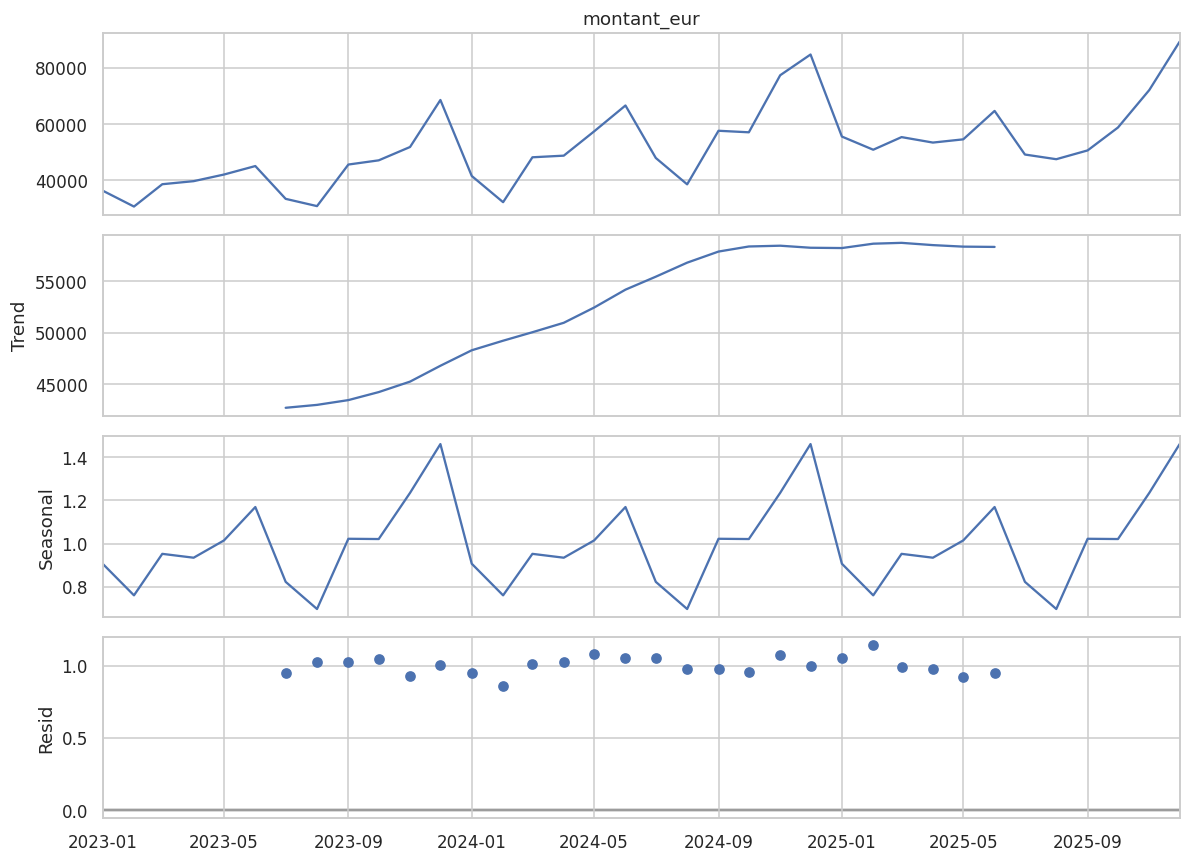

,Mois,Coefficient,Écart au niveau (%)
0,Janvier,0.907,-9.266
1,Février,0.761,-23.867
2,Mars,0.953,-4.713
3,Avril,0.935,-6.493
4,Mai,1.015,1.480
5,Juin,1.169,16.899
6,Juillet,0.824,-17.638
7,Août,0.698,-30.172
8,Septembre,1.022,2.246
9,Octobre,1.021,2.124


Maximum saisonnier : Décembre, coefficient 1.460 ; minimum : Août, coefficient 0.698.


In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose
serie = mensuel.copy()
for mois in cfg["atypiques"]:
    date = pd.Timestamp(mois)
    autres = serie[(serie.index.month == date.month) & (serie.index.year != date.year)]
    if date in serie.index and len(autres):
        serie.loc[date] = autres.mean()
assert serie.gt(0).all(), "Le modèle multiplicatif exige une série strictement positive."
dec = seasonal_decompose(serie, model="multiplicative", period=12)
fig = dec.plot(); fig.set_size_inches(11,8); fig.tight_layout(); plt.show()
coeff = dec.seasonal.groupby(dec.seasonal.index.month).mean()
noms = ["Janvier","Février","Mars","Avril","Mai","Juin","Juillet","Août","Septembre","Octobre","Novembre","Décembre"]
coeff_table = pd.DataFrame({"Mois":noms,"Coefficient":coeff.values,"Écart au niveau (%)":(coeff.values-1)*100})
display(coeff_table.round(3))
print(f"Maximum saisonnier : {noms[int(coeff.idxmax())-1]}, coefficient {coeff.max():.3f} ; minimum : {noms[int(coeff.idxmin())-1]}, coefficient {coeff.min():.3f}.")

**Additif ou multiplicatif ?**

Je retiens un modèle multiplicatif : tous les totaux mensuels sont positifs et les coefficients se lisent en pourcentage du niveau des ventes. Aucun mois atypique n’est listé pour le commerce. Avec trois années et une rupture, les coefficients restent une estimation exploratoire.

## 4. La croissance sur un an
Calculez la croissance par rapport au même mois de l'année précédente (`pct_change(12)`) et tracez-la avec la date de l'événement du brief (`cfg["evenement"]`).

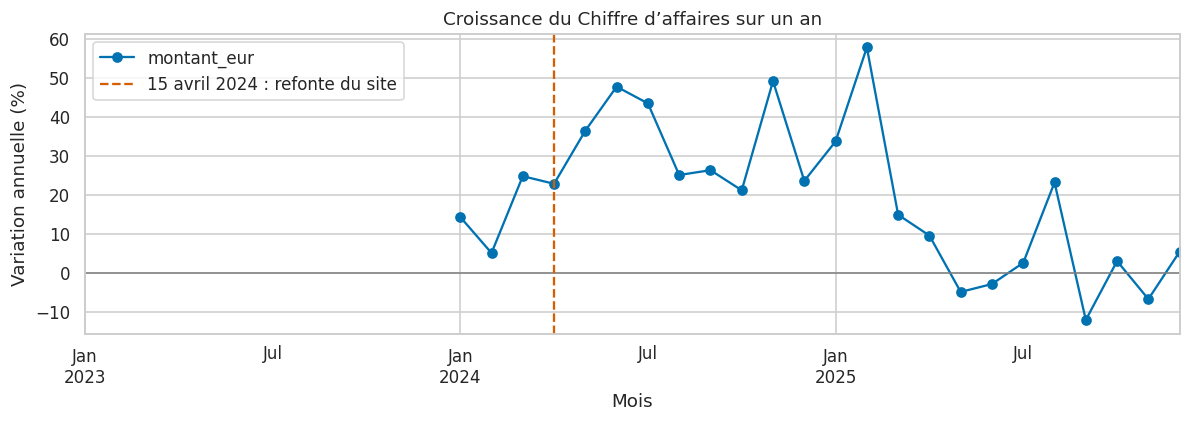

,Croissance annuelle (%)
date_commande,
2024-01-01,14.30
2024-02-01,5.06
2024-03-01,24.76
2024-04-01,22.81
2024-05-01,36.44
2024-06-01,47.72
2024-07-01,43.44
2024-08-01,25.07
2024-09-01,26.30


In [6]:
yoy = mensuel.pct_change(12, fill_method=None)*100
ax = yoy.plot(figsize=(11,4), marker="o", color="#0072B2")
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(evenement, color="#D55E00", linestyle="--", label="15 avril 2024 : refonte du site")
ax.set(title="Croissance du Chiffre d’affaires sur un an", xlabel="Mois", ylabel="Variation annuelle (%)")
ax.legend(); plt.tight_layout(); plt.show()
display(yoy.dropna().round(2).to_frame("Croissance annuelle (%)"))

## 5. Localiser la rupture sans connaître la date
Retirez la saisonnalité (série ÷ coefficient saisonnier), puis cherchez le mois où l'écart entre la moyenne des 6 mois suivants et celle des 6 mois précédents est le plus fort. Vérifiez avec un test de Student.

,avant,apres,ecart
date,,,
2023-07-01,40591.42,44105.19,3513.77
2023-08-01,40677.75,44974.60,4296.84
2023-09-01,41322.07,44670.16,3348.09
2023-10-01,42001.85,45664.55,3662.70
2023-11-01,42612.04,46670.06,4058.02
2023-12-01,42703.98,49097.32,6393.34
2024-01-01,44105.19,50765.32,6660.13
2024-02-01,44974.60,52835.72,7861.13
2024-03-01,44670.16,54986.91,10316.75


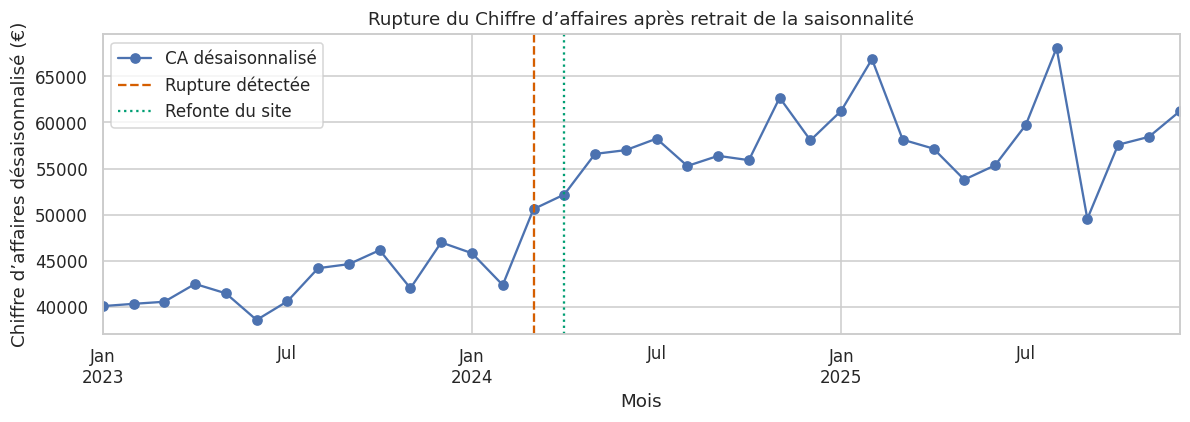

Rupture repérée : 2024-03. Moyenne désaisonnalisée 44,670.16 → 54,986.91 €, soit +23.1 %.
Welch : t=-6.979, p=6.888e-05.
Événement du brief : 2024-04-15 — refonte du site et lancement de l'app.


In [7]:
from scipy import stats
desaison = serie / dec.seasonal
candidats = []
for i in range(6, len(desaison)-5):
    avant = desaison.iloc[i-6:i]
    apres = desaison.iloc[i:i+6]
    candidats.append({"date":desaison.index[i],"avant":avant.mean(),"apres":apres.mean(),"ecart":apres.mean()-avant.mean()})
ruptures = pd.DataFrame(candidats).set_index("date")
rupture = ruptures.ecart.abs().idxmax()
r = ruptures.loc[rupture]
i = desaison.index.get_loc(rupture)
a, b = desaison.iloc[i-6:i], desaison.iloc[i:i+6]
test = stats.ttest_ind(a,b,equal_var=False)
variation_rupture = (r["apres"]/r["avant"]-1)*100
display(ruptures.round(2))
print(f"Rupture repérée : {rupture:%Y-%m}. Moyenne désaisonnalisée {r['avant']:,.2f} → {r['apres']:,.2f} €, soit {variation_rupture:+.1f} %.")
print(f"Welch : t={test.statistic:.3f}, p={test.pvalue:.4g}.")
print(f"Événement du brief : {evenement:%Y-%m-%d} — {cfg['evenement'][1]}.")
ax = desaison.plot(figsize=(11,4), marker="o", label="CA désaisonnalisé")
ax.axvline(rupture,color="#D55E00",label="Rupture détectée",linestyle="--")
if rupture != evenement:
    ax.axvline(evenement,color="#009E73",label="Refonte du site",linestyle=":")
ax.set(title="Rupture du Chiffre d’affaires après retrait de la saisonnalité", xlabel="Mois", ylabel="Chiffre d’affaires désaisonnalisé (€)")
ax.legend();plt.tight_layout();plt.show()

**Lecture de la rupture**

La rupture apparaît en mars 2024, avant la refonte du 15 avril. La comparaison de fenêtres de six mois ne permet pas de dater précisément un effet de la refonte. Le test de Welch reste exploratoire, car le mois est sélectionné après recherche et les observations mensuelles peuvent être dépendantes. Des commandes « app » existent avant le lancement annoncé, ce qui limite l’interprétation de cet événement.

## 6. Expliquer la rupture
Qu'est-ce qui change autour de la rupture ? Comparez la part de chaque segment dans le chiffre d'affaires, par trimestre.

canal,app,magasin,web
trimestre,,,
2023Q1,5.88,62.66,31.46
2023Q2,4.14,65.67,30.18
2023Q3,3.84,60.57,35.59
2023Q4,4.56,61.96,33.48
2024Q1,4.38,62.44,33.18
2024Q2,13.07,44.28,42.65
2024Q3,17.38,40.27,42.35
2024Q4,14.33,42.18,43.48
2025Q1,18.76,43.15,38.09


canal,app,magasin,web
trimestre,,,
2023Q1,6216.92,66257.26,33261.79
2023Q2,5260.56,83360.97,38312.65
2023Q3,4219.02,66600.44,39135.85
2023Q4,7644.42,103855.82,56109.07
2024Q1,5344.12,76218.37,40500.74
2024Q2,22592.04,76544.58,73728.36
2024Q3,25072.12,58074.96,61078.72
2024Q4,31426.50,92479.83,95328.56
2025Q1,30368.50,69858.69,61660.74


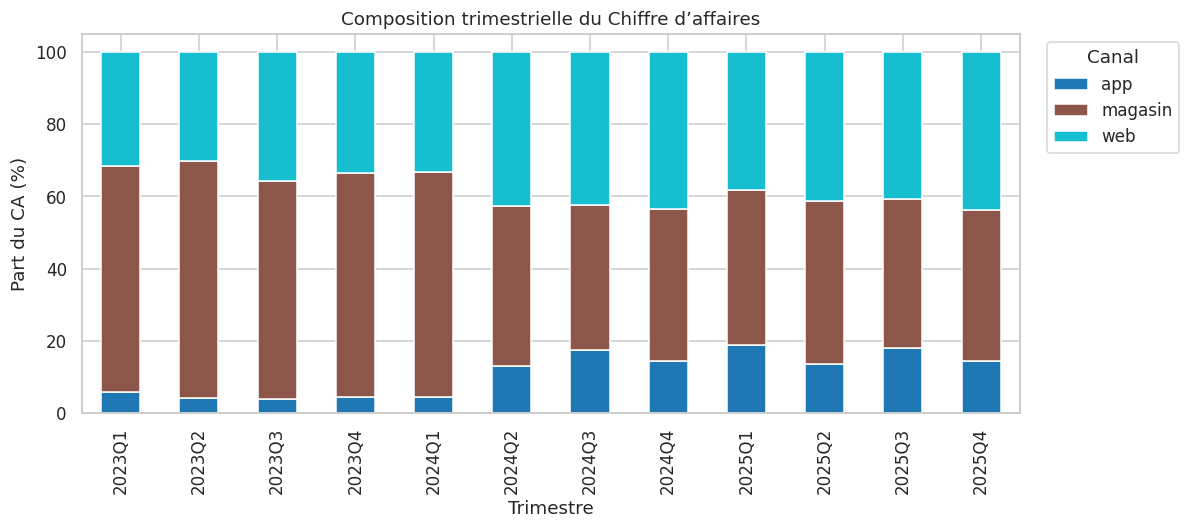

,Avant (€),Après (€),Variation (€),Variation (%)
canal,,,,
app,12620.34,39387.31,26766.97,212.09
magasin,175492.74,145607.62,-29885.12,-17.03
web,98980.77,122669.02,23688.25,23.93


Plus forte contribution positive en euros : app, 26,766.97 €.


In [8]:
trimestriel = df.assign(trimestre=df.date_commande.dt.to_period("Q")).groupby(["trimestre",cfg["segment"]])[cfg["ca"]].sum().unstack(fill_value=0)
parts = trimestriel.div(trimestriel.sum(axis=1),axis=0)*100
display(parts.round(2))
display(trimestriel.round(2))
ax = parts.plot.bar(stacked=True,figsize=(11,5), colormap="tab10")
ax.set(title="Composition trimestrielle du Chiffre d’affaires",xlabel="Trimestre",ylabel="Part du CA (%)")
ax.legend(title="Canal",bbox_to_anchor=(1.02,1));plt.tight_layout();plt.show()
# Même fenêtre de 6 mois de part et d’autre de la rupture détectée.
avant_df = df.loc[df.date_commande.ge(rupture-pd.DateOffset(months=6)) & df.date_commande.lt(rupture)]
apres_df = df.loc[df.date_commande.ge(rupture) & df.date_commande.lt(rupture+pd.DateOffset(months=6))]
segments = pd.concat([avant_df.groupby("canal").montant_eur.sum().rename("Avant (€)"),apres_df.groupby("canal").montant_eur.sum().rename("Après (€)")],axis=1)
segments["Variation (€)"] = segments["Après (€)"]-segments["Avant (€)"]
segments["Variation (%)"] = (segments["Après (€)"]/segments["Avant (€)"]-1)*100
display(segments.round(2))
segment_hausse = segments["Variation (€)"].idxmax()
print(f"Plus forte contribution positive en euros : {segment_hausse}, {segments.loc[segment_hausse,'Variation (€)']:,.2f} €.")

## 7. Bonus · un indicateur de la banque
Pour Crédit Azur, le chiffre d'affaires dépend du **taux d'accord**. Tracez le taux d'accord mensuel : la rupture y est-elle plus nette ?

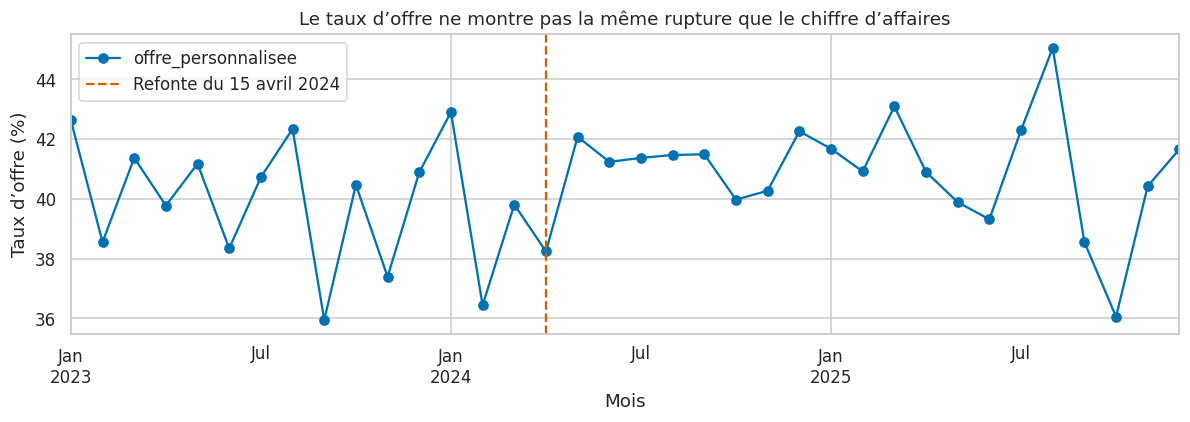

Taux mensuels entre 36.0 % et 45.0 %. Cet indicateur complète le CA sans expliquer à lui seul sa progression.


In [9]:
if SECTEUR=="banque":
    indicateur="credit_accorde"
else:
    indicateur="offre_personnalisee"
taux_mensuel=df.set_index(cfg["date"])[indicateur].resample("MS").mean()*100
ax=taux_mensuel.plot(figsize=(11,4),marker="o",color="#0072B2")
ax.axvline(evenement,color="#D55E00",linestyle="--",label="Refonte du 15 avril 2024")
ax.set(title="Le taux d’offre ne montre pas la même rupture que le chiffre d’affaires",xlabel="Mois",ylabel="Taux d’offre (%)")
ax.legend();plt.tight_layout();plt.show()
print(f"Taux mensuels entre {taux_mensuel.min():.1f} % et {taux_mensuel.max():.1f} %. Cet indicateur complète le CA sans expliquer à lui seul sa progression.")

**Conclusions**

1. Décembre présente le coefficient saisonnier le plus élevé, à **+46,0 %** du niveau désaisonnalisé.
2. La rupture repérée en **mars 2024** correspond à une hausse de **23,1 %** du CA désaisonnalisé entre les deux fenêtres de six mois.
3. Sur ces fenêtres, l’app contribue à la hausse du CA à hauteur de **26 767 €**, sans démontrer un effet causal du lancement.

La comparaison des canaux utilise ici deux fenêtres de six mois autour de la rupture. Elle diffère de la comparaison de l’ensemble des mois complets avant et après la refonte menée dans l’analyse bivariée.

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Séries temporelles : saisonnalité et rupture »